# Getting to know your data

**Worksheet · Data 110 · Fall 2026 · Week 10**
Rebin Muhammad

This is the worksheet for the lecture. Do it in class, after the slides. Run each cell with **Shift+Enter**, from the top.

Under each exercise there is an empty cell. Write your solution in that cell, then run it. This file does not contain the answers.

## How to open this in Google Colab

1. Go to [colab.research.google.com](https://colab.research.google.com).
2. Choose **File → Upload notebook** and select this file.
3. Upload `NCbirths.csv` before you run the data cells. Click the **folder icon** on the left, then the **upload icon**. The name must stay the same. Colab forgets uploaded files when the session ends, so you upload it again next time.


## Setup

pandas holds the tables. matplotlib draws the charts.


In [4]:
import matplotlib.pyplot as plt
import pandas as pd


plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False


## The file

`NCbirths.csv` has one row per birth. There are 1,450 rows and 15 columns. The rows are a sample of births in North Carolina in 2001.

`read_csv` turns the file into a table. It already reads the text `#N/A` as a blank, so `Gained` arrives with missing values. The number `-999` in `Weeks` is kept, because it is a number.


In [5]:
import pandas as pd

births = pd.read_csv('/content/NCbirths.csv')
births.head()

,ID,Plural,Sex,MomAge,Weeks,Marital,RaceMom,HispMom,Gained,Smoke,BirthWeightOz,BirthWeightGm,Low,Premie,MomRace
0,1,1,1,32,40,1,1,N,38.0,0.0,111,3146.85,0,0,white
1,2,1,2,32,37,1,1,N,34.0,0.0,116,3288.60,0,0,white
2,3,1,1,27,39,1,1,N,12.0,0.0,138,3912.30,0,0,white
3,4,1,1,27,39,1,1,N,15.0,0.0,136,3855.60,0,0,white
4,5,1,1,25,39,1,1,N,32.0,0.0,121,3430.35,0,0,white


## 1. How big is the table?

**Exercise.** Print the number of rows and the number of columns.

`shape` is a pair: rows, then columns.

### Your solution

Write your code in the next cell, then run it.


In [6]:
import pandas as pd

births = pd.read_csv("NCbirths.csv")

rows, cols = births.shape
print("Rows:", rows)
print("Columns:", cols)

Rows: 1450
Columns: 15


## 2. Where are the blanks?

**Exercise.** Count the missing values in every column.

`isna` is `True` on a blank cell. `sum` counts those `True` values in each column. A blank is not the same thing as a number such as `-999`.

### Your solution

Write your code in the next cell, then run it.


In [7]:
print(births.isna().sum())

ID                0
Plural            0
Sex               0
MomAge            0
Weeks             0
Marital           0
RaceMom           0
HispMom           0
Gained           40
Smoke             5
BirthWeightOz     0
BirthWeightGm     0
Low               0
Premie            0
MomRace           0
dtype: int64


## 3. The week that cannot be a gestation

**Exercise.** Show the rows where `Weeks` is below 0, and print how many such rows there are.

A completed pregnancy is not a negative number of weeks. In this file that negative number is `-999`.

### Your solution

Write your code in the next cell, then run it.


In [8]:
negative_weeks = births[births["Weeks"] < 0]

print("Number of rows:", len(negative_weeks))
negative_weeks

Number of rows: 1


,ID,Plural,Sex,MomAge,Weeks,Marital,RaceMom,HispMom,Gained,Smoke,BirthWeightOz,BirthWeightGm,Low,Premie,MomRace
1117,1118,1,1,20,-999,2,2,N,NaN,0.0,136,3855.6,0,1,black


## 4. Turn the sentinel into a blank

**Exercise.** On a copy of the table, replace every negative `Weeks` with a missing value. Then print the minimum and the mean of `Weeks`.

`copy` keeps the original `births` table unchanged. `loc` selects the rows. `pd.NA` is a blank. `mean` skips blanks, so the mean changes once `-999` is no longer a number.

### Your solution

Write your code in the next cell, then run it.


In [9]:
births_clean = births.copy()
births_clean.loc[births_clean["Weeks"] < 0, "Weeks"] = pd.NA

print("Minimum Weeks:", births_clean["Weeks"].min())
print("Mean of Weeks:", births_clean["Weeks"].mean())

Minimum Weeks: 22.0
Mean of Weeks: 38.62111801242236


## 5. Turn the sex code into a word

**Exercise.** Add a column `sex_word`. Code `1` becomes `male` and code `2` becomes `female`. Then count the two words.

`map` looks up each number in a dictionary. Use `{1: "male", 2: "female"}`.

### Your solution

Write your code in the next cell, then run it.


In [10]:
births_clean["sex"] = births_clean["Sex"].map({1: "male", 2: "female"})
print(births_clean["sex"].value_counts())

sex
male      744
female    706
Name: count, dtype: int64


## 6. The shape of the real weeks

**Exercise.** Draw a histogram of `Weeks` after the negative value has been replaced with a blank. Use bins that are one week wide. Label the horizontal axis `completed weeks` and the vertical axis `births`.

Drop the blank before you draw, with `dropna`. One bar per week is `bins` set to a sequence of edges one week apart. The real weeks run from 22 to 45.

### Your solution

Write your code in the next cell, then run it.


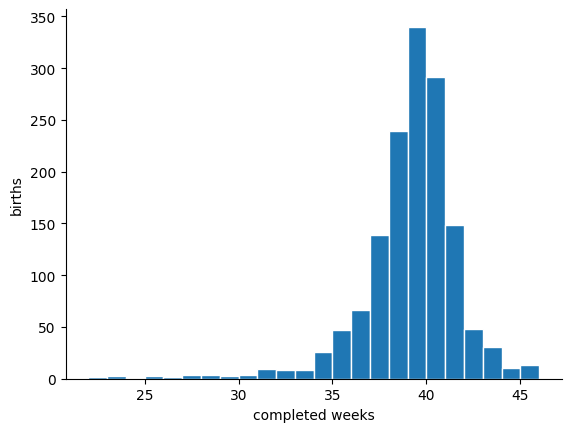

In [11]:
real_weeks = births_clean["Weeks"].dropna()

plt.hist(real_weeks, bins=range(22, 47), edgecolor="white")
plt.xlabel("completed weeks")
plt.ylabel("births")
plt.show()
